In [ ]:
# Optional: Verifying pre-installed dependencies in Google Colab
!pip install numpy opencv-python matplotlib

# Upload image verification check
import os
print("Is input image present?:", os.path.exists("input_image.jpg"))


Is my_image present?: True


In [12]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Load Image
img_path = 'my_image.jpg'
bgr_img = cv.imread(img_path)

if bgr_img is None:
    raise FileNotFoundError(f"Image not found at path: {img_path}")

# Inspection
height, width, channels = bgr_img.shape
dtype = bgr_img.dtype

print(f"Image Shape: {bgr_img.shape}")
print(f"Data Type: {dtype}")
print(f"Dimensions: Height = {height}px, Width = {width}px, Channels = {channels}")

# Indexed Pixel Values
top_left_pixel = bgr_img[0, 0]
center_pixel = bgr_img[height // 2, width // 2]

print(f"Top-Left Pixel (BGR): {top_left_pixel}")
print(f"Center Pixel (BGR): {center_pixel}")

# Global and Per-Channel Min/Max
print(f"Global Min: {bgr_img.min()}, Global Max: {bgr_img.max()}")
for i, col in enumerate(['Blue', 'Green', 'Red']):
    print(f"{col} Channel -> Min: {bgr_img[:, :, i].min()}, Max: {bgr_img[:, :, i].max()}")

Image Shape: (960, 720, 3)
Data Type: uint8
Dimensions: Height = 960px, Width = 720px, Channels = 3
Top-Left Pixel (BGR): [237 239 239]
Center Pixel (BGR): [235 222 176]
Global Min: 0, Global Max: 255
Blue Channel -> Min: 0, Max: 255
Green Channel -> Min: 0, Max: 255
Red Channel -> Min: 0, Max: 255


Center Pixel RGB: [176 222 235] | HEX Code: #b0deeb


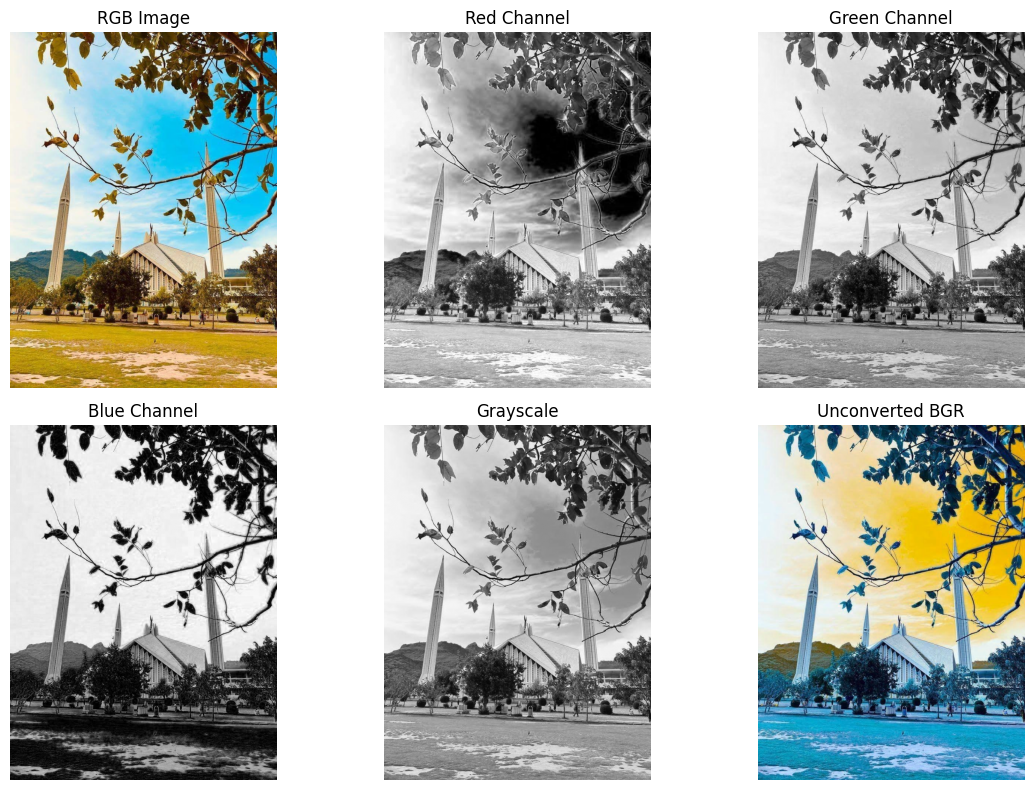

In [16]:
# Color Conversions
rgb_img = cv.cvtColor(bgr_img, cv.COLOR_BGR2RGB)
gray_img = cv.cvtColor(bgr_img, cv.COLOR_BGR2GRAY)

# Separate Channels
r_channel = rgb_img[:, :, 0]
g_channel = rgb_img[:, :, 1]
b_channel = rgb_img[:, :, 2]

# Center Pixel HEX Value
center_rgb = rgb_img[height // 2, width // 2]
hex_value = "#{:02x}{:02x}{:02x}".format(center_rgb[0], center_rgb[1], center_rgb[2])
print(f"Center Pixel RGB: {center_rgb} | HEX Code: {hex_value}")

# Display 2x3 Subplot Grid
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
views = [rgb_img, r_channel, g_channel, b_channel, gray_img, bgr_img]
titles = ['RGB Image', 'Red Channel', 'Green Channel', 'Blue Channel', 'Grayscale', 'Unconverted BGR']

for ax, view, title in zip(axes.ravel(), views, titles):
    if len(view.shape) == 2:
        ax.imshow(view, cmap='gray')
    else:
        ax.imshow(view)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

Crop Shape: (100, 100, 3)


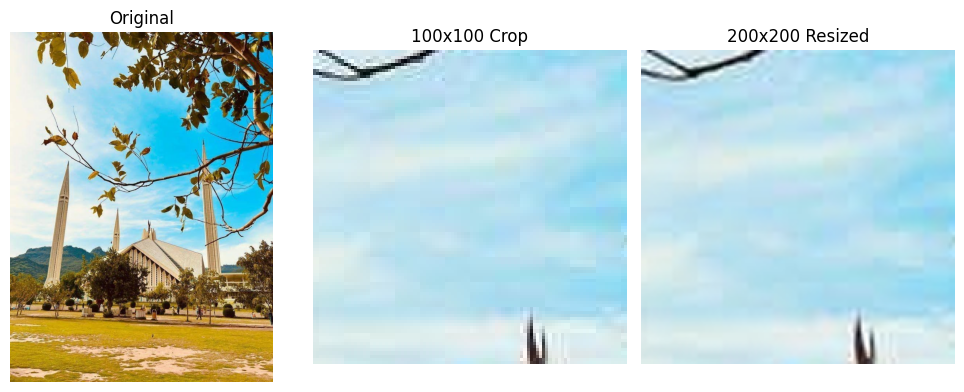

Was 'resized_crop.png' saved successfully? True


In [13]:
# Crop Exact 100x100 Region from Center
y_mid, x_mid = height // 2, width // 2
crop = rgb_img[y_mid - 50 : y_mid + 50, x_mid - 50 : x_mid + 50]
print(f"Crop Shape: {crop.shape}")

# Resize Crop to 200x200
resized = cv.resize(crop, (200, 200), interpolation=cv.INTER_CUBIC)

# Side-by-Side Display
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].imshow(rgb_img); axes[0].set_title('Original')
axes[1].imshow(crop); axes[1].set_title('100x100 Crop')
axes[2].imshow(resized); axes[2].set_title('200x200 Resized')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

# Save File
resized_bgr = cv.cvtColor(resized, cv.COLOR_RGB2BGR)
status = cv.imwrite('resized_crop.png', resized_bgr)
print(f"Was 'resized_crop.png' saved successfully? {status}")

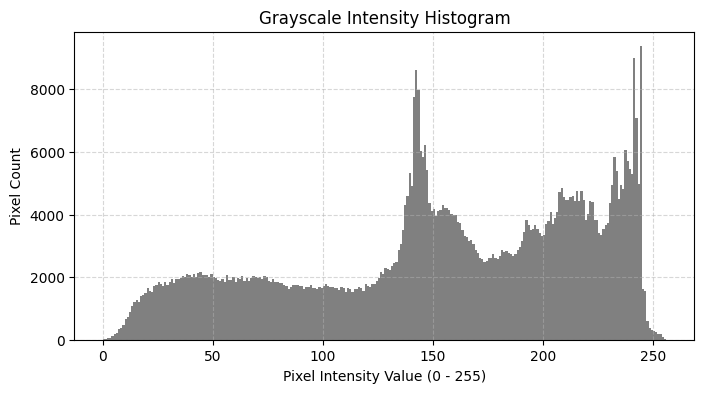

In [17]:
plt.figure(figsize=(8, 4))
plt.hist(gray_img.ravel(), bins=256, range=[0, 256], color='gray')
plt.title('Grayscale Intensity Histogram')
plt.xlabel('Pixel Intensity Value (0 - 255)')
plt.ylabel('Pixel Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('grayscale_histogram.png')
plt.show()

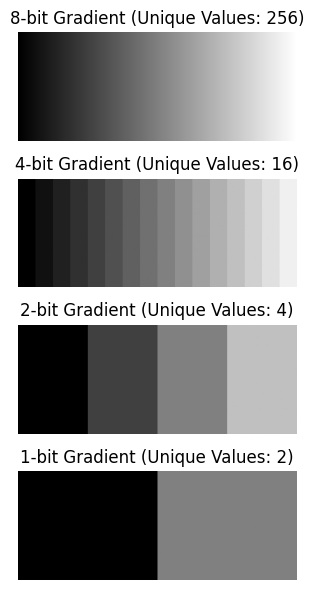

In [18]:
# Create 8-bit Gradient
gradient = np.tile(np.arange(256, dtype=np.uint8), (100, 1))

# Quantize Intensity Levels
grad_4bit = (gradient // 16) * 16
grad_2bit = (gradient // 64) * 64
grad_1bit = (gradient // 128) * 128

# Display Gradient Comparisons
fig, axes = plt.subplots(4, 1, figsize=(8, 6))
grads = [gradient, grad_4bit, grad_2bit, grad_1bit]
titles = [
    f'8-bit Gradient (Unique Values: {len(np.unique(gradient))})',
    f'4-bit Gradient (Unique Values: {len(np.unique(grad_4bit))})',
    f'2-bit Gradient (Unique Values: {len(np.unique(grad_2bit))})',
    f'1-bit Gradient (Unique Values: {len(np.unique(grad_1bit))})'
]

for ax, g, t in zip(axes, grads, titles):
    ax.imshow(g, cmap='gray', vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis('off')

plt.tight_layout()
plt.show()